# Disease Prediction: Breast Cancer Diagnosis from Cell Measurements

**Author:** Irfan Ali

## 1. Problem
Breast cancer is one of the most common cancers in women. A fine needle aspirate (FNA) of a breast mass produces images of cell nuclei, and measurements of those nuclei (size, shape, texture) can help tell a malignant tumour from a benign one.

**Question:** Can a machine learning model use these cell measurements to predict whether a tumour is malignant or benign, and which measurements matter most?

In a medical setting, **missing a cancer (false negative) is worse than a false alarm**, so we pay special attention to *recall* for malignant cases.

## 2. Data
Breast Cancer Wisconsin (Diagnostic) dataset, UCI Machine Learning Repository: 569 patients, 30 numeric features, 1 diagnosis label.
Source: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, recall_score, precision_score, accuracy_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 3. Load and understand the data

In [3]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
# In this dataset target 0 = malignant, 1 = benign. Make it clearer:
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})
df["malignant"] = (df["target"] == 0).astype(int)
df = df.drop(columns="target")

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
df.head()

Shape: (569, 32)
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant,1


diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
diagnosis
Benign       62.7
Malignant    37.3
Name: count, dtype: float64


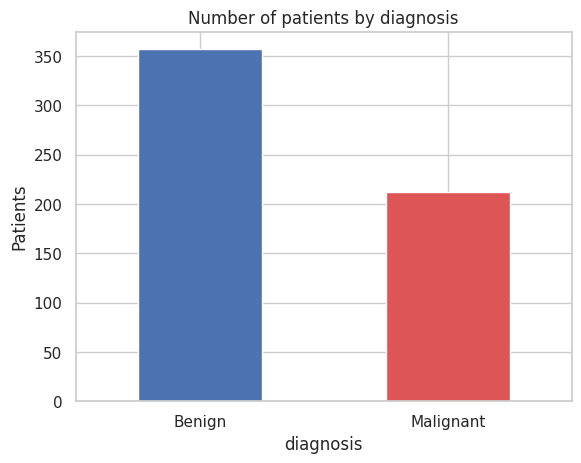

In [4]:
counts = df["diagnosis"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

ax = counts.plot(kind="bar", color=["#4C72B0", "#DD5555"])
ax.set_title("Number of patients by diagnosis")
ax.set_ylabel("Patients")
plt.xticks(rotation=0)
plt.show()

> ✍️ **Your finding:** Are the two classes balanced? What share of patients have a malignant tumour, and why does this matter for how we judge the model?
>
> *Write 2 to 3 sentences here in your own words, then copy them into the Findings section of the README.*

## 4. Exploratory analysis

In [5]:
mean_cols = [c for c in df.columns if c.startswith("mean ")]
df.groupby("diagnosis")[mean_cols].mean().T.round(2)

diagnosis,Benign,Malignant
mean radius,12.15,17.46
mean texture,17.91,21.60
mean perimeter,78.08,115.37
mean area,462.79,978.38
mean smoothness,0.09,0.10
mean compactness,0.08,0.15
mean concavity,0.05,0.16
mean concave points,0.03,0.09
mean symmetry,0.17,0.19
mean fractal dimension,0.06,0.06


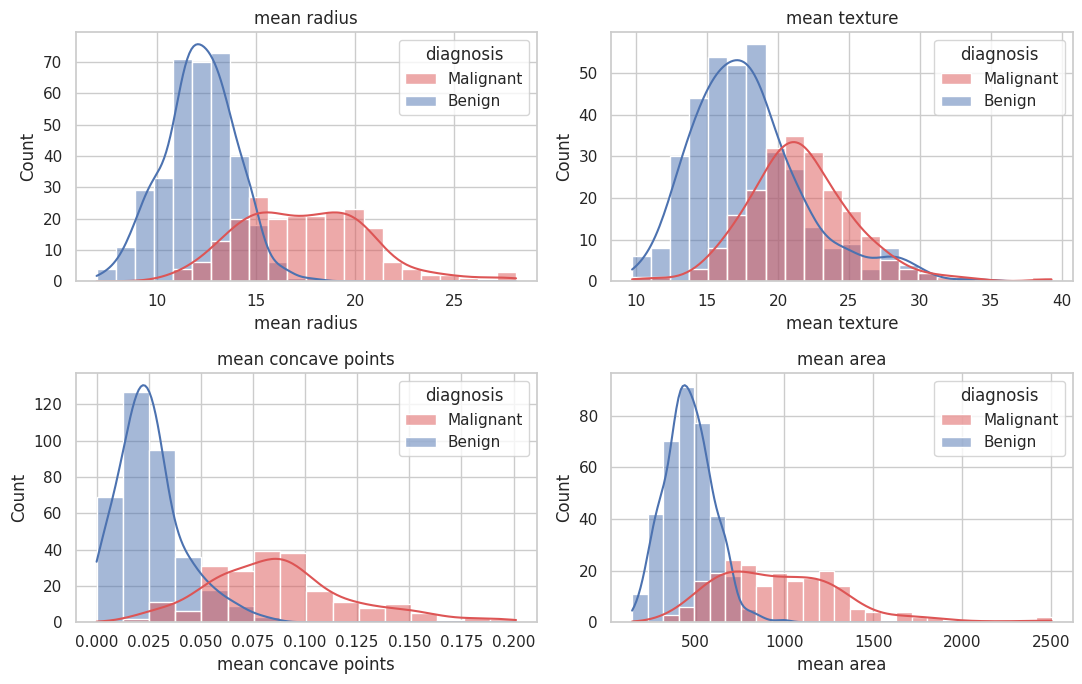

In [6]:
key = ["mean radius", "mean texture", "mean concave points", "mean area"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), key):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, ax=ax, palette={"Benign": "#4C72B0", "Malignant": "#DD5555"})
    ax.set_title(col)
plt.tight_layout()
plt.show()

> ✍️ **Your finding:** Which measurements look most different between malignant and benign tumours? Are malignant tumours larger or smaller on average?
>
> *Write 2 to 3 sentences here in your own words, then copy them into the Findings section of the README.*

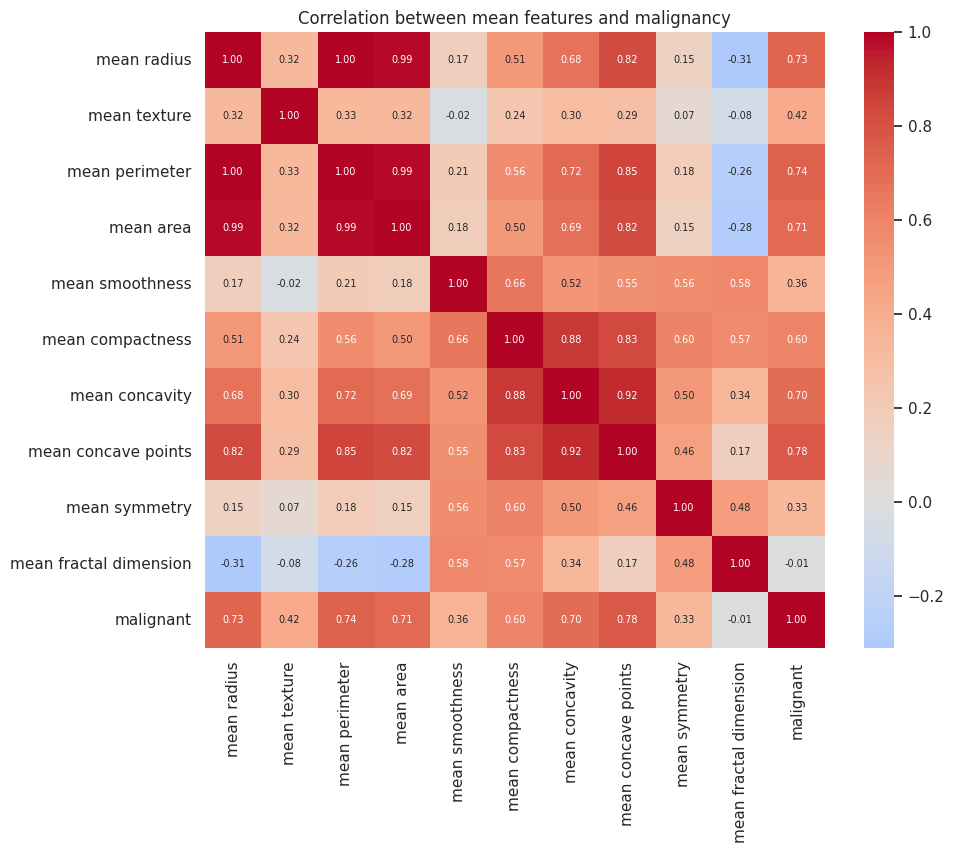

mean concave points       0.78
mean perimeter            0.74
mean radius               0.73
mean area                 0.71
mean concavity            0.70
mean compactness          0.60
mean texture              0.42
mean smoothness           0.36
mean symmetry             0.33
mean fractal dimension   -0.01
Name: malignant, dtype: float64


In [8]:
plt.figure(figsize=(10, 8))
corr = df[mean_cols + ["malignant"]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation between mean features and malignancy")
plt.show()

print(corr["malignant"].drop("malignant").sort_values(ascending=False).round(2))

> ✍️ **Your finding:** Which three features are most strongly correlated with malignancy? Do you notice features that are highly correlated with each other (for example radius, perimeter and area), and why might that be?
>
> *Write 2 to 3 sentences here in your own words, then copy them into the Findings section of the README.*

## 5. Build prediction models

In [9]:
X = df.drop(columns=["diagnosis", "malignant"])
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "CV ROC-AUC (train)": round(cv_auc, 3),
                 "Test accuracy": round(accuracy_score(y_test, pred), 3),
                 "Test recall (malignant)": round(recall_score(y_test, pred), 3),
                 "Test precision (malignant)": round(precision_score(y_test, pred), 3),
                 "Test ROC-AUC": round(roc_auc_score(y_test, prob), 3)})

results = pd.DataFrame(rows)
results

Train: (455, 30)  Test: (114, 30)


,Model,CV ROC-AUC (train),Test accuracy,Test recall (malignant),Test precision (malignant),Test ROC-AUC
0,Logistic Regression,0.996,0.965,0.929,0.975,0.996
1,Random Forest,0.988,0.974,0.929,1.000,0.994


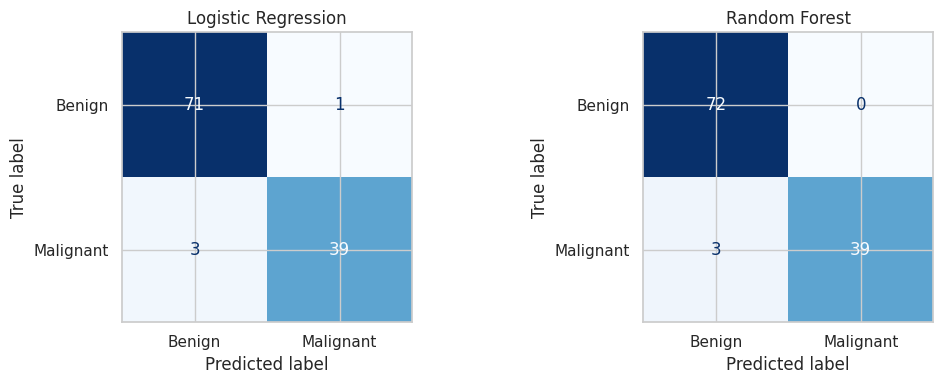

==================== Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

==================== Random Forest
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Benign", "Malignant"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, model in models.items():
    print("=" * 20, name)
    print(classification_report(y_test, model.predict(X_test), target_names=["Benign", "Malignant"]))

> ✍️ **Your finding:** Which model performed better? How many malignant tumours did each model miss (false negatives) in the test set, and why is that number the most important one here?
>
> *Write 2 to 3 sentences here in your own words, then copy them into the Findings section of the README.*

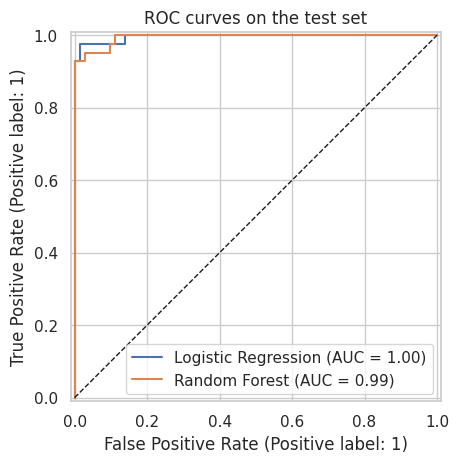

In [12]:
ax = plt.gca()
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("ROC curves on the test set")
plt.show()

## 6. Which features drive the prediction?

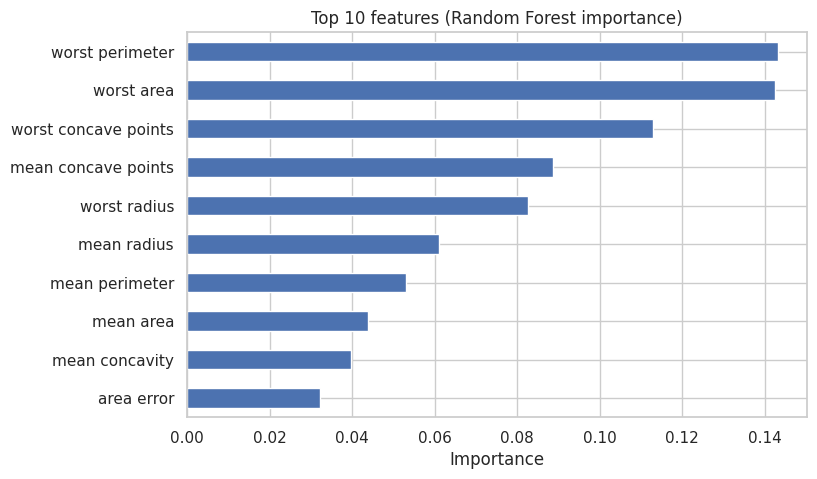

,0
worst perimeter,0.143
worst area,0.142
worst concave points,0.113
mean concave points,0.089
worst radius,0.083
mean radius,0.061
mean perimeter,0.053
mean area,0.044
mean concavity,0.040
area error,0.032


In [11]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).sort_values().plot(kind="barh", color="#4C72B0", figsize=(8, 5))
plt.title("Top 10 features (Random Forest importance)")
plt.xlabel("Importance")
plt.show()
importance.head(10).round(3)

> ✍️ **Your finding:** Which features does the model rely on most? Do they match what you saw in the exploratory analysis?
>
> *Write 2 to 3 sentences here in your own words, then copy them into the Findings section of the README.*

## 7. Export data for Power BI

In [13]:
best = models["Random Forest"]
export = df.copy()
export["predicted_malignant_probability"] = best.predict_proba(X)[:, 1].round(3)
export["set"] = np.where(export.index.isin(X_test.index), "Test", "Train")
export.to_csv("breast_cancer_for_powerbi.csv", index=False)
results.to_csv("model_results_for_powerbi.csv", index=False)
print("Saved breast_cancer_for_powerbi.csv and model_results_for_powerbi.csv")

Saved breast_cancer_for_powerbi.csv and model_results_for_powerbi.csv


## 8. Conclusion and limitations
> ✍️ **Yo:** Summarise in 3 to 4 sentences: what you found, which model you would choose and why, and one limitation (for example: small dataset from one hospital, no external validation, the model supports doctors but does not replace them).

**Next steps (ideas):** test the model on data from another hospital, tune the decision threshold to raise recall, try a smaller set of features.